# 04 · H3 и сравнение методов: чинит ли steering разрыв, и не дешевле ли альтернатива

Полный цикл: база → probe → вектор на train → подбор на val → обучаемые конкуренты
(гейт, TACT, LoRA — train → выбор на val) → сравнение всех методов на val →
заморозка всего набора → test один раз (сравнения, sham-контроли, многошаговые эпизоды).

| метод | что проверяет |
|---|---|
| strong_prompt, restate, explicit_state | хватает ли промпта / пересказа / явного состояния (вердикт ALT) |
| steering | H3: CAA-вектор в окне после ответа |
| steering_gated | тот же вектор, но только когда гейт на активациях предсказывает ошибку |
| tact | адаптация TACT-Gate (2605.05980) |
| lora | H4: дообучение на тех же данных |
| sham:* | контроли H3 |

Запускать после 03, когда H1 и H2 подтверждены. Все решения базы и активации
берутся из кэша 03 — пересчитывается только новое.

> **Протокол** (`docs/HYPOTHESES.md`, `AGENTS.md`): вектор, гейт, оси TACT и LoRA строятся только
> на train, подбор — только на val, test открывается **один раз** на замороженный набор методов.
> Пайплайн это проверяет сам — если ячейка упала с `TestLockError` или `StageOrderError`,
> это защита сработала, а не баг.

In [1]:
%load_ext autoreload
%autoreload 2
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Mac: неподдержанные операции -> CPU

import pandas as pd
from IPython.display import Markdown, display
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

from steering_tool_feedback.config import ExperimentConfig
from steering_tool_feedback.pipeline import Experiment
from steering_tool_feedback import journal, viz

In [2]:
cfg = ExperimentConfig.make(
    name="h3-steering-qwen3-1.7b", hypothesis="H3", notebook="notebooks/04_h3_steering.ipynb",
    notes="Steering (CAA) против промпта, пересказа, явного состояния, гейта, TACT и LoRA.",
    overrides={
        "model.name": "Qwen/Qwen3-1.7B",
        "data.n_tasks": 160,
        "data.generator": "v3",
        "eval.methods": ["baseline", "strong_prompt", "restate", "explicit_state",
                         "steering", "steering_gated", "tact", "lora"],
        "steer.alphas": [0.25, 0.5, 1.0, 2.0, 4.0],
    },
)
exp = Experiment(cfg)
exp.data()
exp.estimate()

/Users/admin/Desktop/steering-tool-feedback/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[00:33:24] run 20261020-003322_h3-steering-qwen3-1.7b_d0d1c7  ->  results/runs/20261020-003322_h3-steering-qwen3-1.7b_d0d1c7
[00:33:24] data: {'train': 79, 'val': 31, 'test': 50}  types={'invariant': 41, 'changing': 112, 'stress': 7}  positions={'early': 114, 'late': 46}
[00:33:24] loading model Qwen/Qwen3-1.7B …


W1020 00:33:28.066000 13528 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:  13%|█▎        | 39/311 [00:00<00:00, 389.86it/s]

Loading weights:  65%|██████▍   | 202/311 [00:00<00:00, 1112.53it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 1159.95it/s]

[00:33:32] estimate: ~104 мин всего (0.29 с на решение, 1.51 с на шаг эпизода, 0.77 с на съём активаций); повторные запуски берут готовое из кэша


,stage,calls,sec_per_call,minutes
0,baseline,220,0.293,1.1
1,probe,158,0.770,2.0
2,sweep,2790,0.293,13.6
3,fit,1178,0.293,5.8
4,test,1700,0.293,8.3
5,episodes,2925,1.509,73.6


baseline/train:   0%|          | 0/158 [00:00<?, ?it/s]

baseline/train:  30%|██▉       | 47/158 [00:00<00:00, 466.77it/s]

baseline/train:  60%|██████    | 95/158 [00:00<00:00, 473.85it/s]

baseline/train:  91%|█████████ | 144/158 [00:00<00:00, 480.49it/s]

[00:33:33] baseline/train: success=0.724  sens=0.545  spec=0.609  unparsed=0


baseline/val:   0%|          | 0/62 [00:00<?, ?it/s]

... (52 outputs left out)

L26/pre_action/a2.0/val:   0%|          | 0/62 [00:00<?, ?it/s]

L26/pre_action/a4.0/val:   0%|          | 0/62 [00:00<?, ?it/s]

[00:33:36] sweep: 45 конфигураций; выбрано L16/pre_action/α=1.0: успех 0.621 → 0.655, Δспециф. -0.000


{'row': {'layer': 16,
  'window': 'pre_action',
  'alpha': 1.0,
  'vector_id': 'cd1d2c657a47',
  'success': 0.6551724137931034,
  'base_success': 0.6206896551724138,
  'sensitivity': 0.631578947368421,
  'specificity': 0.4,
  'spec_drop': 0.0,
  'diff': 0.034482758620689655,
  'ci_low': 0.0,
  'ci_high': 0.08620689655172414,
  'fixed': 2,
  'broken': 0},
 'tolerance': 0.05}

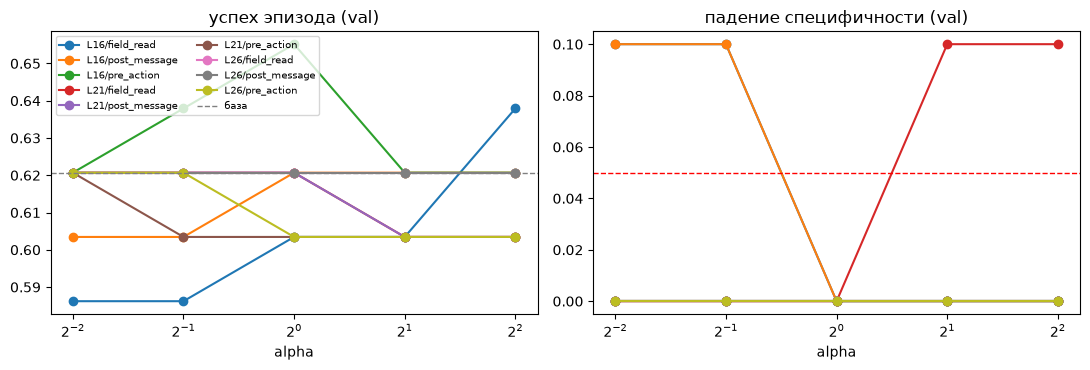

In [3]:
exp.run("sweep")
viz.dose_response(exp.sweep_table(), cfg.steer.max_specificity_drop);
exp.state["selection"]

### Обучаемые конкуренты (train → выбор на val) и все методы на val

Для выбранных методов val оптимистичен: на нём же шёл подбор. Решает только test.

In [4]:
exp.fit()
exp.results_table("val")

activations:   0%|          | 0/156 [00:00<?, ?it/s]

activations:  52%|█████▏    | 81/156 [00:00<00:00, 803.33it/s]

gated L16/field_read/a0.25/t0.3/val:   0%|          | 0/62 [00:00<?, ?it/s]

gated L16/field_read/a0.25/t0.5/val:   0%|          | 0/62 [00:00<?, ?it/s]

gated L16/field_read/a0.25/t0.7/val:   0%|          | 0/62 [00:00<?, ?it/s]

gated L16/field_read/a0.5/t0.3/val:   0%|          | 0/62 [00:00<?, ?it/s]

... (179 outputs left out)

episodes tact/val:   0%|          | 0/58 [00:00<?, ?it/s]

episodes lora/val:   0%|          | 0/58 [00:00<?, ?it/s]

[00:33:49] val: baseline 0.621; strong_prompt 0.569; restate 0.638; explicit_state 0.552; steering 0.655; steering_gated 0.638; tact 0.621; lora 0.948


,method,success,pass^1,sensitivity,specificity,diff_vs_base,ci,fixed,broken,episode,ep_diff,ep_ci,stress,tokens,calls,p50_ms
0,baseline,0.621,0.621,0.526,0.4,NaN,,NaN,NaN,0.586,NaN,,0.50,831,10.0,400.6
1,strong_prompt,0.569,0.569,0.474,0.3,-0.052,"[-0.138, +0.000]",0.0,3.0,0.569,-0.017,"[-0.052, +0.000]",1.00,885,10.0,291.8
2,restate,0.638,0.638,0.526,0.4,0.017,"[-0.069, +0.103]",4.0,3.0,0.586,0.000,"[-0.086, +0.086]",0.50,1765,11.0,1596.1
3,explicit_state,0.552,0.552,0.474,0.1,-0.069,"[-0.207, +0.069]",6.0,10.0,0.466,-0.121,"[-0.276, +0.034]",0.25,1932,11.0,3443.7
4,steering,0.655,0.655,0.632,0.4,0.034,"[+0.000, +0.086]",2.0,0.0,0.603,0.017,"[+0.000, +0.052]",0.50,831,10.0,410.2
5,steering_gated,0.638,0.638,0.579,0.4,0.017,"[+0.000, +0.052]",1.0,0.0,0.603,0.017,"[+0.000, +0.052]",0.50,831,10.0,408.6
6,tact,0.621,0.621,0.526,0.4,0.000,"[+0.000, +0.000]",0.0,0.0,0.586,0.000,"[+0.000, +0.000]",0.50,831,10.0,369.6
7,lora,0.948,0.948,1.000,0.8,0.328,"[+0.190, +0.466]",19.0,0.0,0.828,0.241,"[+0.121, +0.379]",0.00,831,10.0,299.0


In [5]:
for m in ("steering_gated", "tact", "lora"):
    t = exp.fit_table(m)
    if not t.empty:
        display(Markdown(f"**{m}** — подбор на val"))
        display(t.drop(columns=[c for c in ("path", "vector_id", "gate_id", "axes_id") if c in t]))

**steering_gated** — подбор на val

,layer,window,alpha,threshold,gate_on_rate,success,base_success,sensitivity,specificity,spec_drop,diff,ci_low,ci_high,fixed,broken
0,16,field_read,0.25,0.3,0.435,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
1,16,field_read,0.25,0.5,0.323,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
2,16,field_read,0.25,0.7,0.242,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
3,16,field_read,0.50,0.3,0.435,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
4,16,field_read,0.50,0.5,0.323,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,26,pre_action,2.00,0.5,0.258,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
131,26,pre_action,2.00,0.7,0.097,0.621,0.621,0.526,0.4,0.0,0.000,0.000,0.0,0,0
132,26,pre_action,4.00,0.3,0.387,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1
133,26,pre_action,4.00,0.5,0.258,0.603,0.621,0.474,0.4,0.0,-0.017,-0.052,0.0,0,1


**tact** — подбор на val

,lam,k,layers,success,base_success,sensitivity,specificity,spec_drop,diff,ci_low,ci_high,fixed,broken
0,0.5,2.0,"[0, 24, 26, 27]",0.621,0.621,0.526,0.4,0.0,0.0,0.0,0.0,0,0
1,1.0,2.0,"[0, 24, 26, 27]",0.621,0.621,0.526,0.4,0.0,0.0,0.0,0.0,0,0
2,1.5,2.0,"[0, 24, 26, 27]",0.621,0.621,0.526,0.4,0.0,0.0,0.0,0.0,0,0
3,2.0,2.0,"[0, 24, 26, 27]",0.621,0.621,0.526,0.4,0.0,0.0,0.0,0.0,0,0


**lora** — подбор на val

,lr,epochs,adapter_id,train_seconds,n_examples,n_trainable,success,base_success,sensitivity,specificity,spec_drop,diff,ci_low,ci_high,fixed,broken
0,1.000e-04,2,7307bc4e8b7d,676.2,110,3211264,0.724,0.621,0.684,0.5,-0.1,0.103,0.034,0.207,6,0
1,3.000e-04,2,684a01bfec65,671.9,110,3211264,0.948,0.621,1.000,0.8,-0.4,0.328,0.190,0.466,19,0


In [6]:
for h, v in exp.verdicts().items():   # предварительно, по val
    print(f"{h}: {v.label:18} {v.reason}")

H1: ✔ support          лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573
H2: ✔ support          различает (H1), но ошибается в 47% меняющих пар: чувствительность 0.526, специфичность 0.400
H3: ? inconclusive (val) на val: успех 0.621 → 0.655 при L16/pre_action/α=1.0; решает только test
H4: ✘ against (val)    LoRA не хуже steering на условном срезе: steering − LoRA -0.293 [-0.431, -0.155]
ALT: ? inconclusive (val) то же качество, что у steering, но дороже: restate (steering − restate +0.017 [-0.052, +0.086]), но дороже: p50 1596 vs 410 мс; explicit_state (steering − explicit_state +0.103 [-0.034, +0.241]), но дороже: p50 3444 vs 410 мс


### Промежуточный вывод по val → журнал

Подбор закончен, test ещё закрыт. Запись фиксирует, что было видно **до** открытия test. При повторном запуске ноутбука ради test поставь `VAL_REPORT = False`, чтобы не дублировать запись.

In [7]:
VAL_REPORT = True
if VAL_REPORT:
    display(Markdown(exp.report(
        conclusion="""**Предварительно, по val** (29 задач; для выбранных методов val оптимистичен — на нём же
шёл подбор). Test не открыт.

- **steering** (CAA, L16/pre_action/α=1): успех 0.621 → 0.655, +0.034 [0.000, +0.086], 2 исправлено /
  0 сломано, специфичность без изменений (0.40); эпизоды 0.586 → 0.603. Эффект на грани нуля;
  диагностика — в журнале (насыщение при α ≥ 4, уверенные ошибки не сдвигаются).
- **steering с гейтом**: 0.638; **адаптация TACT**: 0.621 — ни одного изменённого решения (оси на
  слоях 0, 24, 26, 27 по AUC на val; λ не влияет).
- **Промпт-методы не помогают**: сильный промпт 0.569 (−0.052), пересказ 0.638 (+0.017, задержка в 4 раза
  больше), явное состояние 0.552 (−0.069; специфичность падает до 0.10, эпизоды −0.121).
- **LoRA на тех же данных** (110 примеров меняющих пар train, lr 3e-4, 2 эпохи, 11 мин на M4): 0.948,
  +0.328 [+0.190, +0.466], чувствительность 1.00, специфичность 0.80, 19 исправлено / 0 сломано;
  эпизоды 0.828 (+0.241 [+0.121, +0.379]). Побочный эффект: стресс-пары 0/4 (у базы 2/4).

Вердикты (val): H3 — inconclusive; **H4 — against**: steering − LoRA = −0.293 [−0.431, −0.155];
ALT — inconclusive (пересказ не хуже steering, но дороже по задержке).

Чтение: модель «знает», что товар не подходит под требование (05: AUROC ≈ 0.98 перед действием), но
CAA-вектор по верным/неверным решениям этот разрыв почти не закрывает, а LoRA на тех же примерах
закрывает почти полностью. На этом сеттинге утверждение 2604.14090 о преимуществе steering для
условных изменений пока не подтверждается. Оговорки: LoRA учится на тех же шаблонах, что и val
(перенос на новые шаблоны не проверен); n мал; это val, а не test.""",
        next_step="""Решение Павла: открывать ли test (один раз) для замороженного набора методов. До test —
разведочно, на train/val: (1) перенос LoRA и steering на шаблоны, которых не было в train (новый тип
требования), — это и есть вопрос «условное vs глобальное»; (2) вариант steering, нацеленный на механизм
разрыва (контраст внутри задачи «подходит / не подходит»), — только как отдельный метод с подбором на val.
Определить глобальный срез для H4.""",
    )))

## 2026-10-20 00:33 · прогон `20261020-003322_h3-steering-qwen3-1.7b_d0d1c7`

**Гипотеза:** H3 · **Ноутбук:** notebooks/04_h3_steering.ipynb · **Модель:** Qwen/Qwen3-1.7B (mps, float16) · **Режим решения:** scored
**Стадии:** data, baseline, probe, vectors, sweep, fit · **git:** `3d2526b` (есть незакоммиченные изменения)

**Зачем:** Steering (CAA) против промпта, пересказа, явного состояния, гейта, TACT и LoRA.

**Отличия от конфига по умолчанию:** `data.n_tasks` = 160; `eval.methods` = ['baseline', 'strong_prompt', 'restate', 'explicit_state', 'steering', 'steering_gated', 'tact', 'lora']; `model.name` = 'Qwen/Qwen3-1.7B'

**⚠ Флаги протокола:**
- незакоммиченные изменения в src/docs/notebooks/configs — прогон не воспроизводится по коммиту

**Результаты (val):**

| method | success | sensitivity | specificity | diff_vs_base | ci | fixed | broken | episode | ep_diff | tokens | calls | p50_ms |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.621 | 0.526 | 0.400 | — |  | — | — | 0.586 | — | 831 | 10.000 | 400.600 |
| strong_prompt | 0.569 | 0.474 | 0.300 | -0.052 | [-0.138, +0.000] | 0.000 | 3.000 | 0.569 | -0.017 | 885 | 10.000 | 291.800 |
| restate | 0.638 | 0.526 | 0.400 | 0.017 | [-0.069, +0.103] | 4.000 | 3.000 | 0.586 | 0.000 | 1765 | 11.000 | 1596.100 |
| explicit_state | 0.552 | 0.474 | 0.100 | -0.069 | [-0.207, +0.069] | 6.000 | 10.000 | 0.466 | -0.121 | 1932 | 11.000 | 3443.700 |
| steering | 0.655 | 0.632 | 0.400 | 0.034 | [+0.000, +0.086] | 2.000 | 0.000 | 0.603 | 0.017 | 831 | 10.000 | 410.200 |
| steering_gated | 0.638 | 0.579 | 0.400 | 0.017 | [+0.000, +0.052] | 1.000 | 0.000 | 0.603 | 0.017 | 831 | 10.000 | 408.600 |
| tact | 0.621 | 0.526 | 0.400 | 0.000 | [+0.000, +0.000] | 0.000 | 0.000 | 0.586 | 0.000 | 831 | 10.000 | 369.600 |
| lora | 0.948 | 1.000 | 0.800 | 0.328 | [+0.190, +0.466] | 19.000 | 0.000 | 0.828 | 0.241 | 831 | 10.000 | 299.000 |

**Вердикты (автоматически, по правилам HYPOTHESES.md):**
- H1: ✔ support — лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573
- H2: ✔ support — различает (H1), но ошибается в 47% меняющих пар: чувствительность 0.526, специфичность 0.400
- H3: ? inconclusive (val) — на val: успех 0.621 → 0.655 при L16/pre_action/α=1.0; решает только test
- H4: ✘ against (val) — LoRA не хуже steering на условном срезе: steering − LoRA -0.293 [-0.431, -0.155]
- ALT: ? inconclusive (val) — то же качество, что у steering, но дороже: restate (steering − restate +0.017 [-0.052, +0.086]), но дороже: p50 1596 vs 410 мс; explicit_state (steering − explicit_state +0.103 [-0.034, +0.241]), но дороже: p50 3444 vs 410 мс

**Вывод:** **Предварительно, по val** (29 задач; для выбранных методов val оптимистичен — на нём же
шёл подбор). Test не открыт.

- **steering** (CAA, L16/pre_action/α=1): успех 0.621 → 0.655, +0.034 [0.000, +0.086], 2 исправлено /
  0 сломано, специфичность без изменений (0.40); эпизоды 0.586 → 0.603. Эффект на грани нуля;
  диагностика — в журнале (насыщение при α ≥ 4, уверенные ошибки не сдвигаются).
- **steering с гейтом**: 0.638; **адаптация TACT**: 0.621 — ни одного изменённого решения (оси на
  слоях 0, 24, 26, 27 по AUC на val; λ не влияет).
- **Промпт-методы не помогают**: сильный промпт 0.569 (−0.052), пересказ 0.638 (+0.017, задержка в 4 раза
  больше), явное состояние 0.552 (−0.069; специфичность падает до 0.10, эпизоды −0.121).
- **LoRA на тех же данных** (110 примеров меняющих пар train, lr 3e-4, 2 эпохи, 11 мин на M4): 0.948,
  +0.328 [+0.190, +0.466], чувствительность 1.00, специфичность 0.80, 19 исправлено / 0 сломано;
  эпизоды 0.828 (+0.241 [+0.121, +0.379]). Побочный эффект: стресс-пары 0/4 (у базы 2/4).

Вердикты (val): H3 — inconclusive; **H4 — against**: steering − LoRA = −0.293 [−0.431, −0.155];
ALT — inconclusive (пересказ не хуже steering, но дороже по задержке).

Чтение: модель «знает», что товар не подходит под требование (05: AUROC ≈ 0.98 перед действием), но
CAA-вектор по верным/неверным решениям этот разрыв почти не закрывает, а LoRA на тех же примерах
закрывает почти полностью. На этом сеттинге утверждение 2604.14090 о преимуществе steering для
условных изменений пока не подтверждается. Оговорки: LoRA учится на тех же шаблонах, что и val
(перенос на новые шаблоны не проверен); n мал; это val, а не test.

**Следующий шаг:** Решение Павла: открывать ли test (один раз) для замороженного набора методов. До test —
разведочно, на train/val: (1) перенос LoRA и steering на шаблоны, которых не было в train (новый тип
требования), — это и есть вопрос «условное vs глобальное»; (2) вариант steering, нацеленный на механизм
разрыва (контраст внутри задачи «подходит / не подходит»), — только как отдельный метод с подбором на val.
Определить глобальный срез для H4.


### Test — один раз. Дальше этой ячейки конфиг не меняется.

Открывать, только когда результаты val просмотрены и решение принято: повторное открытие для того же набора методов заблокировано, а для другого — помечается в журнале.

In [ ]:
exp.freeze()
exp.test()
viz.compare_methods(exp.results_table("test"));
exp.results_table("test")

In [ ]:
for h, v in exp.verdicts().items():
    print(f"{h}: {v.label:16} {v.reason}")

In [ ]:
display(Markdown(exp.report(
    conclusion="""…""",
    next_step="""…""",
)))